# 05 · Daytime visits: where do Kota Yogyakarta's daytime visitors live?

Output 2 (applied analysis). The question for a user of the data, such as a transport planner: which kapanewon send the most daytime visitors into the city, and which city kapanewon do they visit? The dashboard (`dashboard/app.py`) lets a user pick any origin or destination.

Input: `od_dec_feb` (December 2021 to February 2022; March and April are flagged `reduced_quality` in the source and left out). One row is a home kapanewon (origin) and a kapanewon where its devices were seen between 08:00 and 17:59 (destination) in a month. `n_maids` counts devices, `n_homed_maids` counts devices whose home is the origin that month, and `visit_rate` is their ratio.

A device can visit several destinations in a month, so visit rates summed over destinations exceed 1. Two measures follow from that:

- City visit rate (`src/applied.py`, `city_visits`): the sum of `visit_rate` over the 14 Kota Yogyakarta kapanewon, read as "city kapanewon visited per home device per month".
- City share: city visits as a share of all visits outside the origin kapanewon. This removes differences in how much devices from each origin move at all, which also changes from month to month as the panel changes.

Pairs with fewer than 5 devices are suppressed, so small origins lose their rare destinations first.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import CITY_KAB_CODE as CITY, FIGURES as FIG, KAB_ORDER, N_KAPANEWON, OD_GOOD_MONTHS, PROCESSED
from applied import MIN_HOMED, city_visits, ranked_origins

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 160, "display.max_columns", 30)
JP_COL = "#0F766E"            # slide colours (presentation/slides_plan.md)
FIGSIZE = (12.8, 7.2)         # 1920 x 1080 at 150 dpi
KAB_COL = dict(zip(KAB_ORDER, sns.color_palette("Set2", len(KAB_ORDER))))

od = pd.read_parquet(PROCESSED / "od_dec_feb.parquet")
od["month"] = od.month.astype(str)
assert sorted(od.month.unique()) == OD_GOOD_MONTHS
assert od.origin_code.nunique() == N_KAPANEWON
assert not od.duplicated(["month", "origin_code", "dest_code"]).any()
names = od.drop_duplicates("origin_code").set_index("origin_code")[["origin_kab_kota", "origin_kapanewon"]]
names.columns = ["kab_kota", "kapanewon"]

def savefig(fig, name):
    fig.savefig(FIG / f"visits_{name}.png")

print(f"{len(od):,} origin-destination-month rows, {od.origin_code.nunique()} origins, months {OD_GOOD_MONTHS}")

7,872 origin-destination-month rows, 78 origins, months ['2021-12', '2022-01', '2022-02']


## 1. City visit rate and city share per origin and month

In [2]:
homed = od.drop_duplicates(["month", "origin_code"]).pivot(index="origin_code", columns="month",
                                                           values="n_homed_maids")
away = od[~od.is_intra]
cv = city_visits(od)
city_rate = cv.city_rate.unstack()
city_share = cv.city_share.unstack()
print("Home devices per origin and month:")
display(homed.describe().round(0))
ranked = ranked_origins(od)
print(f"Origins with >= {MIN_HOMED} home devices in every month: {len(ranked)} of {len(homed)}")
print("Left out:", ", ".join(names.loc[homed.index.difference(ranked), "kapanewon"].str.title()))

outside = ranked[names.loc[ranked, "kab_kota"] != "YOGYAKARTA"]
print("\nMonth-to-month Spearman of city share, origins outside the city:")
display(city_share.loc[outside].corr(method="spearman").round(2))
print("Median city visit rate by month, origins outside the city (rises as the panel changes):")
print(city_rate.loc[outside].median().round(3).to_dict())

Home devices per origin and month:


month,2021-12,2022-01,2022-02
count,78.0,78.0,78.0
mean,1566.0,1103.0,996.0
std,2082.0,1425.0,1368.0
min,26.0,48.0,30.0
25%,332.0,233.0,180.0
50%,809.0,598.0,436.0
75%,1633.0,1269.0,1100.0
max,9495.0,8217.0,7336.0


Origins with >= 100 home devices in every month: 65 of 78
Left out: Patuk, Paliyan, Panggang, Tepus, Rongkop, Ngawen, Saptosari, Girisubo, Tanjungsari, Purwosari, Gedongtengen, Ngampilan, Wirobrajan

Month-to-month Spearman of city share, origins outside the city:


month,2021-12,2022-01,2022-02
month,,,
2021-12,1.00,0.63,0.41
2022-01,0.63,1.00,0.85
2022-02,0.41,0.85,1.00


Median city visit rate by month, origins outside the city (rises as the panel changes):
{'2021-12': 0.093, '2022-01': 0.129, '2022-02': 0.182}


## 2. Origins outside the city

In [3]:
res = pd.DataFrame({
    "city share (%)": city_share.loc[outside].mean(axis=1),
    "city visit rate": city_rate.loc[outside].mean(axis=1),
    "home devices (mean)": homed.loc[outside].mean(axis=1).round(0),
    "rank Dec": city_share.loc[outside, "2021-12"].rank(ascending=False),
    "rank Feb": city_share.loc[outside, "2022-02"].rank(ascending=False),
}).join(names).sort_values("city share (%)", ascending=False)
display(res.head(15).round(2))
print("By kabupaten (median over its ranked kapanewon):")
kab_tbl = res.groupby("kab_kota")[["city share (%)", "city visit rate"]].median().reindex(KAB_ORDER[1:]).round(2)
kab_tbl["kapanewon ranked"] = res.kab_kota.value_counts()
display(kab_tbl)

,city share (%),city visit rate,home devices (mean),rank Dec,rank Feb,kab_kota,kapanewon
origin_code,,,,,,,
34.02.12,38.22,0.61,5334.0,1.0,3.0,BANTUL,BANGUNTAPAN
34.02.15,38.09,0.55,2571.0,2.0,1.0,BANTUL,SEWON
34.02.16,35.53,0.41,5473.0,3.0,2.0,BANTUL,KASIHAN
34.04.07,28.80,0.36,8349.0,4.0,4.0,SLEMAN,DEPOK
34.04.01,27.22,0.41,5655.0,5.0,5.0,SLEMAN,GAMPING
34.04.06,25.46,0.38,3234.0,10.0,6.0,SLEMAN,MLATI
34.04.13,24.80,0.26,2290.0,9.0,7.0,SLEMAN,SLEMAN
34.04.08,23.80,0.40,1086.0,6.0,9.0,SLEMAN,BERBAH
34.02.13,19.82,0.22,1021.0,24.0,8.0,BANTUL,PLERET


By kabupaten (median over its ranked kapanewon):


,city share (%),city visit rate,kapanewon ranked
kab_kota,,,
SLEMAN,15.18,0.19,17
BANTUL,13.91,0.13,17
KULON PROGO,10.56,0.10,12
GUNUNGKIDUL,9.33,0.07,8


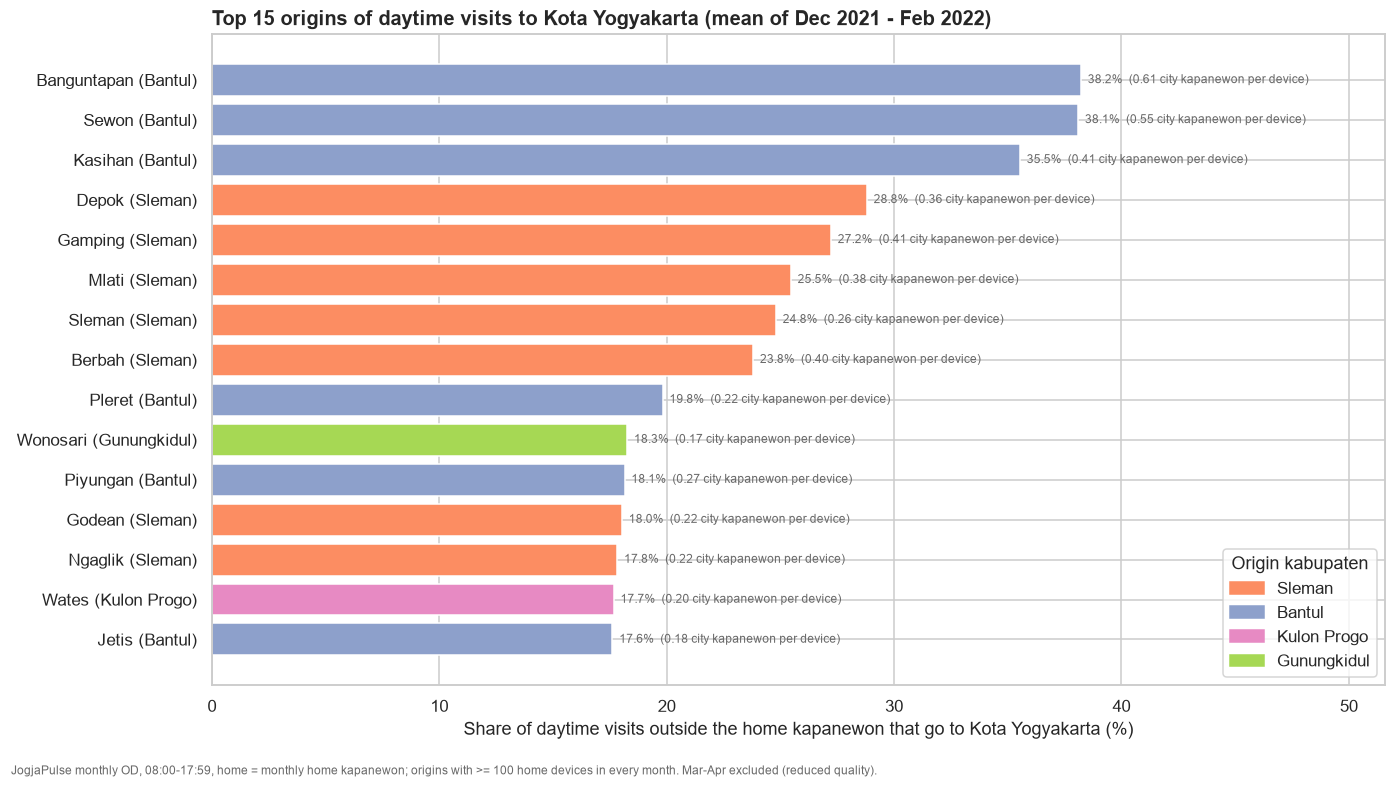

In [4]:
show = res.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.barh(np.arange(len(show)), show["city share (%)"], color=[KAB_COL[k] for k in show.kab_kota])
ax.set_yticks(np.arange(len(show)), [f"{r.kapanewon.title()} ({r.kab_kota.title()})" for r in show.itertuples()])
for i, r in enumerate(show.itertuples()):
    ax.text(r[1] + .3, i, f"{r[1]:.1f}%  ({r[2]:.2f} city kapanewon per device)", va="center", fontsize=8,
            color="dimgrey")
handles = [plt.Rectangle((0, 0), 1, 1, color=KAB_COL[k]) for k in KAB_ORDER[1:]]
ax.legend(handles, [k.title() for k in KAB_ORDER[1:]], loc="lower right", title="Origin kabupaten")
ax.set_xlabel("Share of daytime visits outside the home kapanewon that go to Kota Yogyakarta (%)")
ax.set_xlim(0, show["city share (%)"].max() * 1.35)
ax.set_title(f"Top 15 origins of daytime visits to Kota Yogyakarta (mean of Dec 2021 - Feb 2022)", loc="left")
fig.text(.01, .01, f"JogjaPulse monthly OD, 08:00-17:59, home = monthly home kapanewon; origins with >= {MIN_HOMED} "
         "home devices in every month. Mar-Apr excluded (reduced quality).", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "top_origins")

## 3. Which city kapanewon do they visit?

Mean visit rate (Dec–Feb) from the 12 origins with the highest city share to each of the 14 city kapanewon.

Mean visit rate to each city kapanewon, averaged over the 12 origins:
dest_code
UMBULHARJO      6.1
GONDOKUSUMAN    4.9
GONDOMANAN      3.8
KOTAGEDE        3.2
JETIS           3.2
TEGALREJO       2.4
MERGANGSAN      2.2
DANUREJAN       1.8
KRATON          1.8
MANTRIJERON     1.6
WIROBRAJAN      1.3
GEDONGTENGEN    1.2
PAKUALAMAN      1.1
NGAMPILAN       0.9


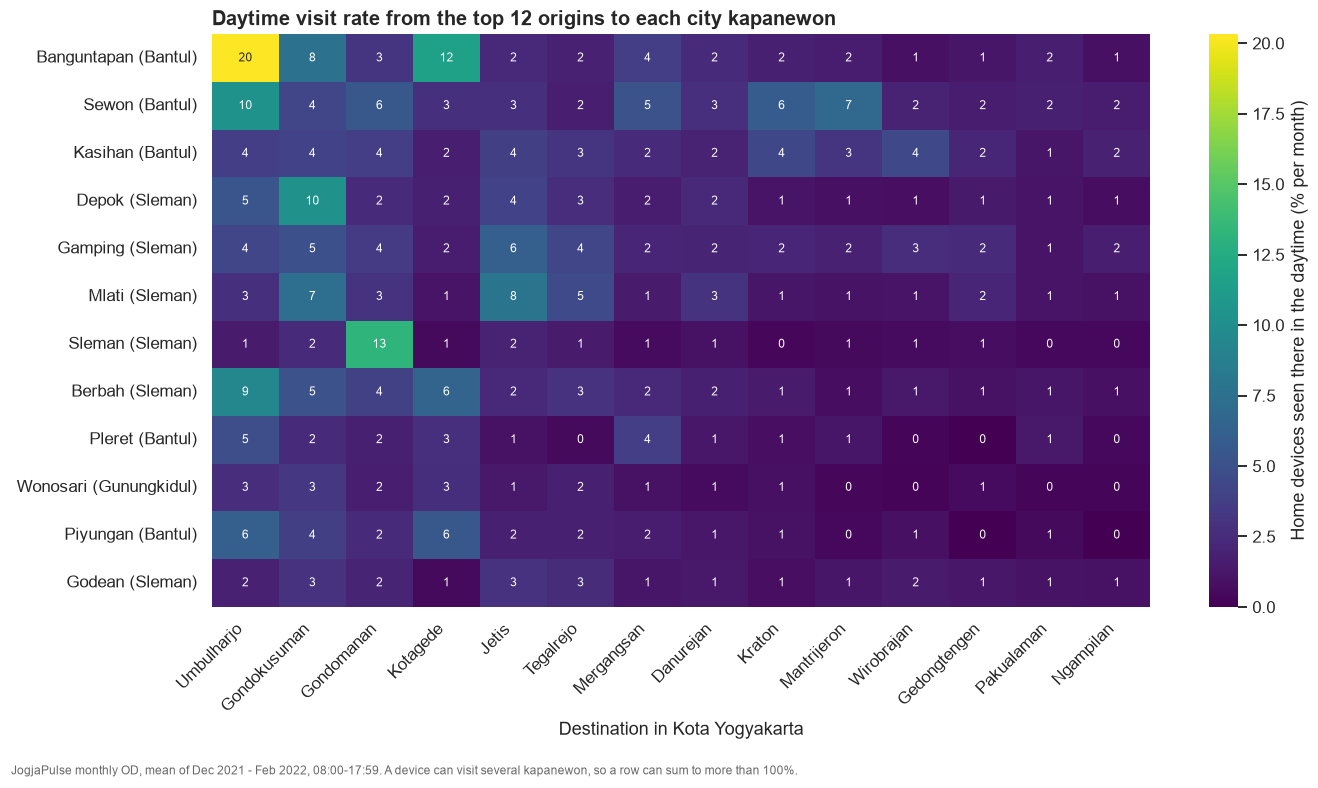

In [5]:
top12 = res.index[:12]
pair = (away[away.origin_code.isin(top12) & (away.dest_kab_code == CITY)]
        .pivot_table(index="origin_code", columns="dest_code", values="visit_rate", aggfunc="sum")
        .div(len(OD_GOOD_MONTHS)))   # mean over months; a missing month counts as 0 (suppressed)
pair = pair.reindex(top12).fillna(0)
dest_names = od.drop_duplicates("dest_code").set_index("dest_code").dest_kapanewon
pair = pair[pair.mean().sort_values(ascending=False).index]
print("Mean visit rate to each city kapanewon, averaged over the 12 origins:")
print((pair.mean() * 100).round(1).rename(dest_names).to_string())

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.heatmap(pair * 100, ax=ax, cmap="viridis", annot=True, fmt=".0f", annot_kws={"fontsize": 8},
            cbar_kws={"label": "Home devices seen there in the daytime (% per month)"})
ax.set_xticklabels([dest_names[c].title() for c in pair.columns], rotation=45, ha="right")
ax.set_yticklabels([f"{names.kapanewon[c].title()} ({names.kab_kota[c].title()})" for c in pair.index], rotation=0)
ax.set_xlabel("Destination in Kota Yogyakarta")
ax.set_ylabel("")
ax.set_title("Daytime visit rate from the top 12 origins to each city kapanewon", loc="left")
fig.text(.01, .01, "JogjaPulse monthly OD, mean of Dec 2021 - Feb 2022, 08:00-17:59. A device can visit several "
         "kapanewon, so a row can sum to more than 100%.", fontsize=8, color="dimgrey")
fig.tight_layout(rect=(0, .03, 1, 1))
savefig(fig, "origin_destination_heatmap")

## 4. Summary numbers for the script

In [6]:
for r in res.head(3).itertuples():
    print(f"{r.kapanewon.title()} ({r.kab_kota.title()}): city share {r[1]:.1f}%, "
          f"{r[2]:.2f} city kapanewon visited per home device per month")
print("Kabupaten medians (city share %):", kab_tbl["city share (%)"].to_dict())
print(f"Most visited city kapanewon from the top 12 origins: "
      f"{dest_names[pair.columns[0]].title()} ({pair.mean().iloc[0] * 100:.0f}% of home devices per month), "
      f"{dest_names[pair.columns[1]].title()} ({pair.mean().iloc[1] * 100:.0f}%)")
r = city_share.loc[outside].corr(method="spearman")
print(f"Month-to-month Spearman of city share: Dec-Jan {r.iloc[0, 1]:.2f}, Jan-Feb {r.iloc[1, 2]:.2f}, Dec-Feb {r.iloc[0, 2]:.2f}")

Banguntapan (Bantul): city share 38.2%, 0.61 city kapanewon visited per home device per month
Sewon (Bantul): city share 38.1%, 0.55 city kapanewon visited per home device per month
Kasihan (Bantul): city share 35.5%, 0.41 city kapanewon visited per home device per month
Kabupaten medians (city share %): {'SLEMAN': 15.18, 'BANTUL': 13.91, 'KULON PROGO': 10.56, 'GUNUNGKIDUL': 9.33}
Most visited city kapanewon from the top 12 origins: Umbulharjo (6% of home devices per month), Gondokusuman (5%)
Month-to-month Spearman of city share: Dec-Jan 0.63, Jan-Feb 0.85, Dec-Feb 0.41


Interpretation (wording follows the numbers printed above):

- The kapanewon that send the largest share of their daytime visits to Kota Yogyakarta border the city: Banguntapan (38.2%), Sewon (38.1%) and Kasihan (35.5%) in Bantul, then Depok (28.8%) and Gamping (27.2%) in Sleman. The same 5 are ranked 1 to 5 in both December and February.
- By kabupaten, the median city share is 15.2% for Sleman, 13.9% for Bantul, 10.6% for Kulon Progo and 9.3% for Gunungkidul. Wonosari (18.3%) and Wates (17.7%), the two kabupaten capitals, are in the top 15 despite their distance.
- Within the city, Umbulharjo and Gondokusuman receive the most visits from the top 12 origins (6% and 5% of home devices per month). Flows follow neighbours: Banguntapan to Umbulharjo (20%) and Kotagede (12%), Depok to Gondokusuman (10%). Sleman to Gondomanan (13%) stands out and is not explained here.
- Rankings are stable from January to February (Spearman 0.85) and less so from December (0.41 Dec-Feb). December has the largest panel and the year-end holidays.
- Visit rates rise from a median of 0.093 city kapanewon per home device in December to 0.182 in February for all origins, which is likely a panel effect, so the city share is the measure to quote.
- "Daytime visit" means a device seen there between 08:00 and 17:59 at least once in the month. It does not separate work from school, shopping or leisure, so the slide says daytime visitors, not commuters.